#### Plot the triangle glyph matrix for bias correction comparison

In [ ]:
# load modules
import pandas as pd
import numpy as np
import Path
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import get_cmap
from matplotlib.colors import TwoSlopeNorm
import matplotlib as mpl

# set filepaths
DATA_DIR = Path("Data/")

methods = ["CDF-t", "EC-BC", "R2D2", "MBCn", "TSMBC"]
metrics = ["ME_TMAX", "MAE_TMAX", "RMSE_TMAX", "Corr_TMAX", "ME_TMIN", "MAE_TMIN", "RMSE_TMIN", "Corr_TMIN", "Corr_TMXMN"]

In [ ]:
f = np.load(DATA_DIR + "bias_corr_metric.npz", allow_pickle=True)

# absolute improvement values
delta_abs = f["data_abs"]
delta_rel = f["data_rel"]

# convert to DataFrame object
df = pd.DataFrame(delta_rel, index=methods, columns=metrics)
df_abs = pd.DataFrame(delta_abs, index=methods, columns=metrics)

vals = df.to_numpy(dtype=float)
abs_vals = df_abs.to_numpy(dtype=float)

#### plot heatmap

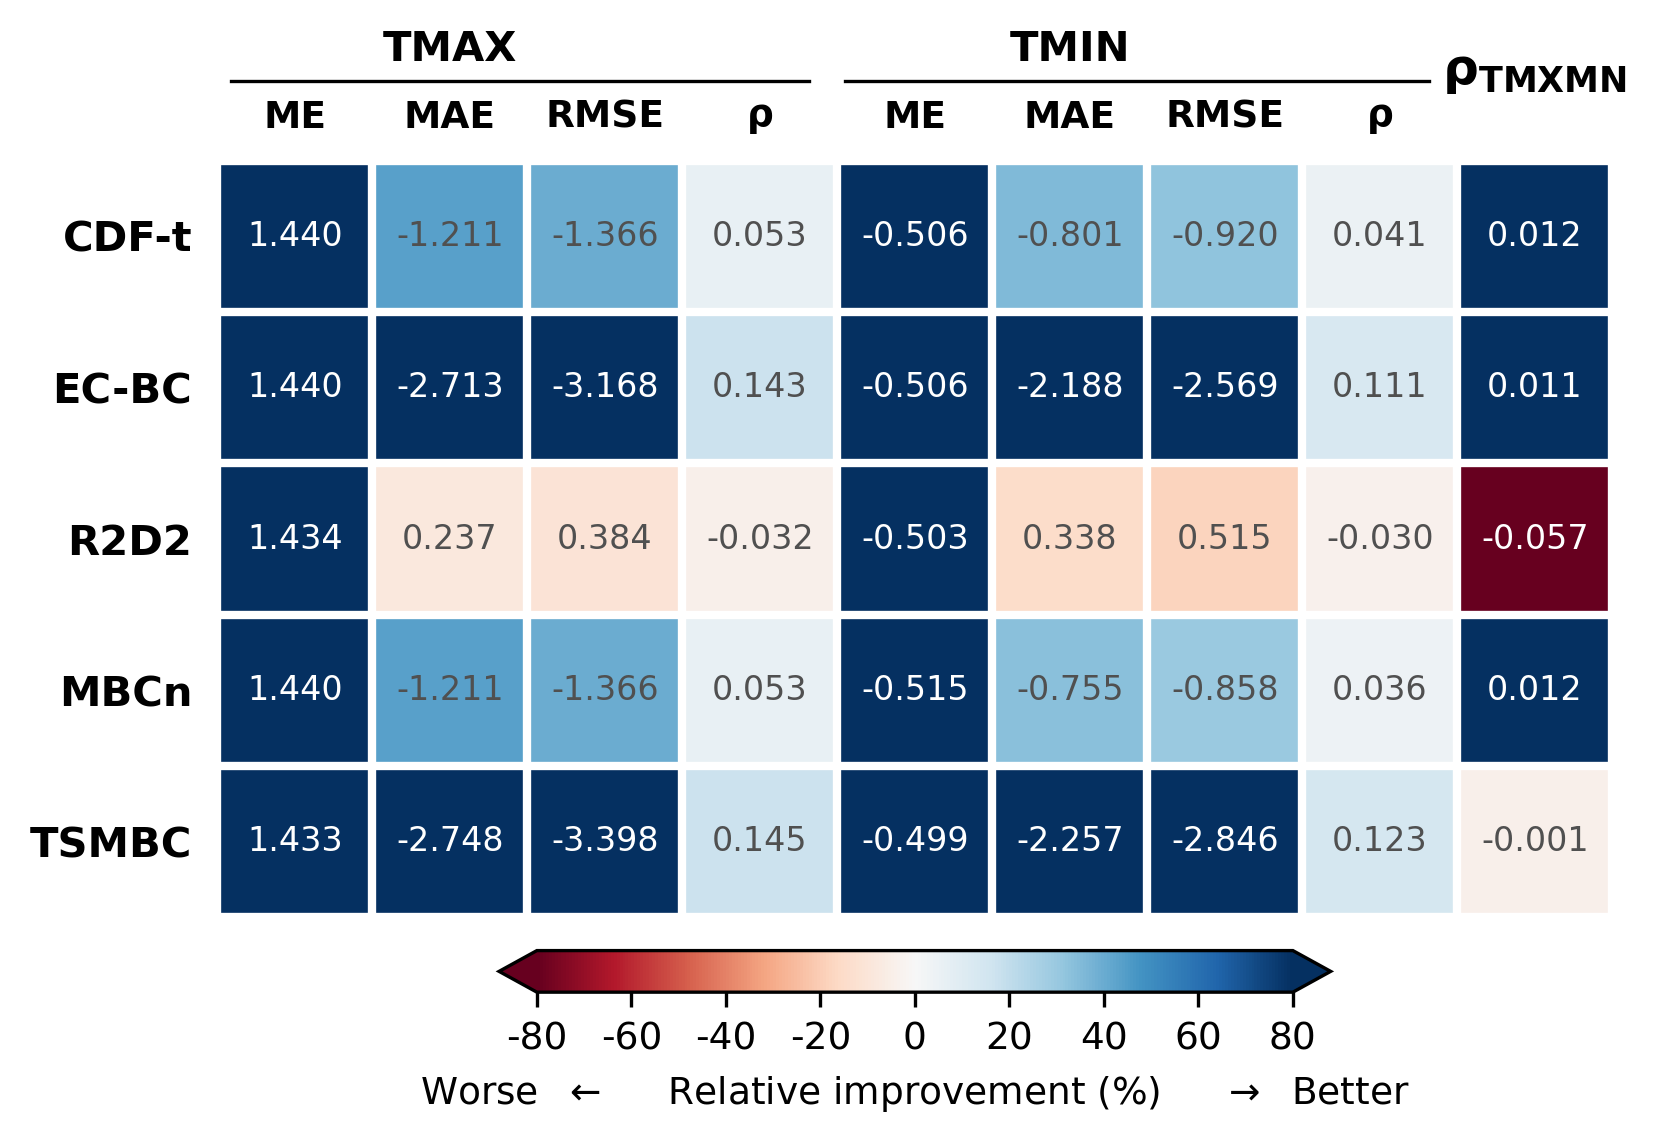

In [4]:
nrow, ncol = vals.shape

fig, ax = plt.subplots(figsize=(6, 3.6), dpi=300)

norm = TwoSlopeNorm(vmin=-0.8, vcenter=0, vmax=0.8)
# reverse rows for display
im = ax.imshow(vals[:, :], cmap="RdBu", norm=norm, aspect="auto", interpolation="none")

display_abs = abs_vals[:, :]
display_rel = vals[:, :]

for i in range(nrow):
    for j in range(ncol):
        value = display_abs[i, j]
        rel = display_rel[i, j]
        # choose annotation color
        if abs(rel) > 0.6:
            txtcolor = "white"
        else:
            txtcolor = "#505050"

        ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=8, color=txtcolor)

# axis labels
ax.set_xticks(np.arange(ncol))
ax.set_yticks(np.arange(nrow))
xticklabels = ["ME", "MAE", "RMSE", r"$\mathbf{\rho}$", "ME", "MAE", "RMSE", r"$\mathbf{\rho}$", ""]
ax.set_xticklabels(xticklabels, fontsize=9, fontweight="bold")
ax.set_yticklabels(methods, fontsize=10, fontweight="bold")
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False, length=0, pad=6)

# add light grid
ax.set_xticks(np.arange(-0.5, ncol, 1), minor=True)
ax.set_yticks(np.arange(-0.5, nrow, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

# group headers
group_y = 1.12
ax.text(1.5/9, group_y, "TMAX", transform=ax.transAxes, ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.text(5.5/9, group_y, "TMIN", transform=ax.transAxes, ha="center", va="bottom", fontsize=10, fontweight="bold")

line_y = 1.105
ax.plot([0.01, 4.0/9-0.02],[line_y, line_y], transform=ax.transAxes, color="black",lw=0.8,clip_on=False)
ax.plot([4.05/9, 8.0/9-0.02],[line_y, line_y], transform=ax.transAxes, color="black",lw=0.8,clip_on=False)
#ax.plot([8.05/9, 1.00],[line_y, line_y], transform=ax.transAxes, color="black",lw=0.8,clip_on=False)
ax.text(8.5/9, line_y-0.02, r"$\mathbf{\rho}_{\mathbf{TMXMN}}$", transform=ax.transAxes, ha="center", va="bottom", fontsize=12, fontweight="bold")

# colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
ticks = np.array([-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8])
cbar=plt.colorbar(sm, ax=ax, shrink=0.9, fraction=0.05, pad=0.04, extend="both", orientation="horizontal", ticks=ticks)
#cbar.set_label("Relative improvement", fontsize=10)
cbar.set_label(r"Worse  $\leftarrow$     Relative improvement (%)     $\rightarrow$  Better", fontsize=9)
cbar.set_ticklabels([f"{int(t*100)}" for t in ticks], fontsize=9)
cbar.ax.tick_params(labelsize=9)

# clean spines
for s in ax.spines.values():
    s.set_visible(False)
